# Uma revisão sobre vetores

Vimos que podemos organizar nossas medições discretas em uma coleção de dados (ou um **vetor**). Além disso, frequentemente, o modelo matemático pode ser **linear**. Isso implica que teremos uma versão matricial de um problema físico, dada por

\begin{equation}
\mathbf{b}= \mathbf{A} \mathbf{x} + \mathbf{n},
\tag{1}
\end{equation}

em que 

- $\mathbf{b} = \left[b_1, b_2, \cdots b_M\right]^T \in \mathbb{C}^{M \times 1}$ é o vetor de observações (ou medições); ele contém uma série de números (reais ou, de forma genérica, complexos);
- $\mathbf{A} \in \mathbb{C}^{M \times L}$ é a matriz de sensibilidade do problema; ela contém uma série de números (ou coeficientes), que são computados pela função $f(\mathbf{\Theta}, \mathbf{r},t)$ medidos discretamente nas variáveis independentes;
- $\mathbf{x} = \left[x_1, x_2, \cdots x_L\right]^T \in \mathbb{C}^{L \times 1}$ é o vetor de coeficientes de $\mathbf{\Theta}$ com a solução desejada do problema inverso.
- $\mathbf{n} \in \mathbb{C}^{M \times 1}$ é o ruído associado à medição (frequentemente desconhecido).

Vamos começar pensando em vetores reais e bidimensionais e discutir um tópico de suma importância: o **produto interno** (dot product).

# Produto interno (Inner product / dot product)

Vamos discutir a noção de operação chamada **produto interno**. Esta é uma importante tecnologia matemática que usamos amplamente no processamento de sinais e nas operações com matrizes. 

## O caso mais simples (bidimensional):

Considere dois vetores $\vec{a}$ e $\vec{b}$, por ora reais e bidimensionais ($\in \mathbb{R}^{2}$). Portanto, podemos dizer que: 

\begin{equation}
\vec{a} \in \mathbb{R}^2,
\end{equation}
e 

\begin{equation}
\vec{b} \in \mathbb{R}^2,
\end{equation}

O produto interno entre $\vec{a}$ e $\vec{b}$ é

\begin{equation}
\vec{a} \cdot \vec{b} = \left\|\vec{a}\right\|  \left\|\vec{b}\right\| \cos{\theta} \ \ \in \mathbb{R},
\tag{2}
\end{equation}
em que 

- $\theta$ é o ângulo entre os vetores,
- $\left\|\vec{a}\right\| = \sqrt{a_x^2+a_y^2}$ é a norma **Euclidiana** ($\mathcal{\ell}_2$) de $\vec{a}$.

Escrito de outra forma:

\begin{equation}
\vec{a} \cdot \frac{\vec{b}}{\left\|\vec{b}\right\|} = \left\|\vec{a}\right\| \ \cos{\theta}
\tag{3}
\end{equation}

### IMPORTANTE:

Note então que o produto interno entre $\vec{a}$ e o vetor unitário $\frac{\vec{b}}{\left\|\vec{b}\right\|}$ mensura o **tamanho da projeção de** $\vec{a}$ **na direção de** $\vec{b}$. 

Note que podemos ver $\vec{b}$ (neste contexto) como uma **base** de referência para $\vec{a}$. Deste ponto de vista, podemos pensar em medir o tamanho de $\vec{a}$ na direção de $\vec{b}$.

Vamos ver alguns exemplos.

In [1]:
# importar as bibliotecas necessárias
import numpy as np # arrays
import matplotlib.pyplot as plt # plots

Dot product is: 50.000000000000000
Angle between vectors is: 0.000000 deg


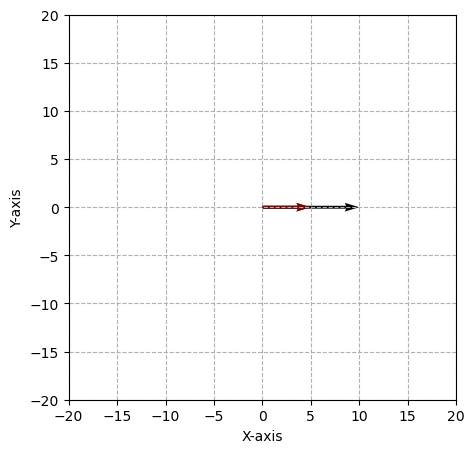

In [4]:
# 2D Vectors
a = np.array([5, 10])
b = np.array([13, 3])

#a = np.array([0, 10.379843])
#b = np.array([10.379843, 0])

#a = np.array([10, 0])
#b = np.array([5, 0])

# Lengths
a_norm = np.linalg.norm(a)
b_norm = np.linalg.norm(b)

# dot product
dot_prod = np.dot(a, b)

# angle
theta = np.arccos(dot_prod/(a_norm*b_norm))

# projection in b direction
proj = b*np.cos(theta)

# print info
print("Dot product is: {:.15f}".format(dot_prod))
print("Angle between vectors is: {:.6f} deg".format(np.rad2deg(theta)))

# plot
plt.figure(figsize = (5,5))
plt.quiver(0, 0, a[0], a[1], angles='xy', scale_units='xy', scale=1, color='k')
plt.quiver(0, 0, b[0], b[1], angles='xy', scale_units='xy', scale=1, color='k')
plt.quiver(0, 0, proj[0], proj[1], angles='xy', scale_units='xy', scale=1, color='r', alpha = 0.5)
plt.xlim((-20, 20))
plt.ylim((-20, 20))
# Add grid and labels
plt.grid(linestyle = '--')
plt.xlabel('X-axis')
plt.ylabel('Y-axis');

## Casos especiais

Do exemplo anterior, se  $\vec{a}$ e $\vec{b}$ estiverem na mesma direção, então $\cos(\theta) = \pm 1$ (já que $\theta = 0$ ou $\theta = \pi$). Logo,

\begin{equation}
\vec{a} \cdot \vec{b} = \pm\left\|\vec{a}\right\|  \left\|\vec{b}\right\| .
\end{equation}

Se  $\vec{a}$ e $\vec{b}$ forem **ortogonais**, $\theta = \pi/2$ ou $\theta = 3\pi/2$. Logo, 

\begin{equation}
\vec{a} \cdot \vec{b} = 0
\tag{4}
\end{equation}


## Por que este raciocínio de projeção é útil?

Porque você pode decompor seu vetor em componentes mais simples. De fato, um vetor 2D pode ser decomposto em vetores unitários 

- $\hat{x} = (1,0)$
- $\hat{y} = (0,1)$

Que são entre si **ortogonais**. Portanto, formam uma boa base vetorial pra representar vetores $\in \mathbb{R}^2$. 

C:\Users\Win11\anaconda3\Lib\site-packages\matplotlib\quiver.py:648: RuntimeWarning: invalid value encountered in divide
  lengths = np.hypot(*dxy.T) / eps


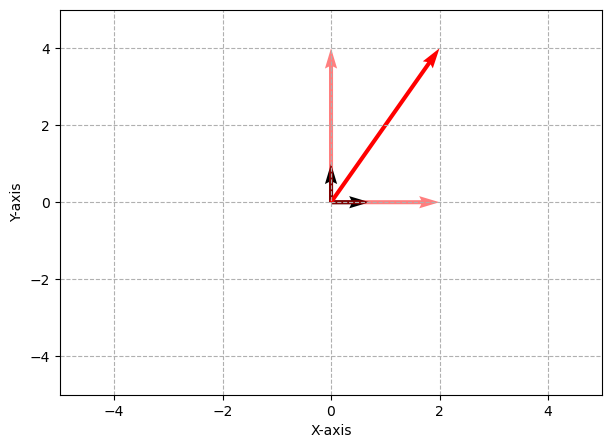

In [5]:
hat_x = np.array([1, 0])
hat_y = np.array([0, 1])

# 2D Vectors
a = np.array([2, 4])
a_proj_x = hat_x * np.dot(a,hat_x)
a_proj_y = hat_y * np.dot(a,hat_y)

# plot
plt.figure(figsize = (7,5))
plt.quiver(0, 0, hat_x[0], hat_x[1], angles='xy', scale_units='y', scale=1, color='k')
plt.quiver(0, 0, hat_y[0], hat_y[1], angles='xy', scale_units='xy', scale=1, color='k')
plt.quiver(0, 0, a[0], a[1], angles='xy', scale_units='xy', scale=1, color='r', alpha = 1)
plt.quiver(0, 0, a_proj_x[0], a_proj_x[1], angles='xy', scale_units='xy', scale=1, color='r', alpha = 0.5)
plt.quiver(0, 0, a_proj_y[0], a_proj_y[1], angles='xy', scale_units='xy', scale=1, color='r', alpha = 0.5)
plt.xlim((-5, 5))
plt.ylim((-5, 5))
# Add grid and labels
plt.grid(linestyle = '--')
plt.xlabel('X-axis')
plt.ylabel('Y-axis');

## E se não usarmos uma base ortogonal? 

Embora ainda seja possível representar qualquer vetor de forma única, você abandona a simplicidade de um sistema ortogonal. 

- Independência dos componentes: alterar um componente de um vetor geralmente altera seu comprimento e ângulo de forma que se correlacionam com o outro eixo, reduzindo a eficiência na computação numérica.E se não usarmos uma base ortogonal? 


**O que você perde?**

- Extração simples de componentes: você não pode mais encontrar os componentes de um vetor ($a_i \neq \vec{a} \cdot \vec{e}_1$).
- Fórmula da distância pitagórica (agora você vai precisar envolver os ângulos dos eixos).
- Independência dos componentes: alterar um componente de um vetor geralmente altera seu comprimento e ângulo de uma forma que se correlaciona com o outro eixo, reduzindo a eficiência em computação numérica.

**O que você mantem?**
- As regras fundamentais da álgebra linear de adição vetorial e multiplicação escalar permanecem válidas.
- Representação única: Qualquer vetor ainda pode ser expresso de forma única como uma combinação linear.
- Independência linear: Os vetores base ainda são linearmente independentes, o que significa que eles abrangem o espaço 2D.

## Computação discreta

O produto interno pode também ser computado da seguinte forma

\begin{equation}
\vec{a}  \cdot \vec{b}  = a_1 * b_1 + a_2*b_2
\end{equation}
em que $\vec{a} = [a_1,  a_2]^T$ e $\vec{b}  = [b_1, b_2]^T$.

In [6]:
# 2D Vectors
a = np.array([5, 10])
b = np.array([13, 3])
# dot product - 1rst way
dot_prod1 = np.dot(a, b)
# dot product - 2nd way
dot_prod2 = a[0]*b[0] + a[1]*b[1]

print("Dot product (way 1) is: {:.6f}".format(dot_prod1))
print("Dot product (way 2) is: {:.6f}".format(dot_prod2))

Dot product (way 1) is: 95.000000
Dot product (way 2) is: 95.000000


# Norma Euclidiana ($\mathcal{\ell}_2$)

A norma Euclidiana (ou norma $\mathcal{\ell}_2$) pode ser definida a partir do produto interno do vetor com ele mesmo. Isto é equivalente a tomar o teorema de Pitágoras e calcular a hipotenusa de um triângulo retângulo, cujos catetos são a projeção de $\mathbf{a}$ nos eixos $\hat{x}$ e $\hat{y}$.

\begin{equation}
\left\|\vec{a}\right\|_2^2 = \vec{a} \cdot \vec{a} = \sum\limits_{i = 1}^{2} a_{i}^{2}
\tag{5}
\end{equation}

In [7]:
# 2D Vectors
a = np.array([5, 10])
# Lengths
a_norm1 = np.linalg.norm(a)
a_norm2 = np.dot(a,a)

print("L2 norm (way 1) is: {:.12f}".format(a_norm1))
print("L2 norm (way 2) is: {:.12f}".format(np.sqrt(a_norm2)))

L2 norm (way 1) is: 11.180339887499
L2 norm (way 2) is: 11.180339887499


# Múltiplas dimensões

Nós podemos estender o mesmo raciocínio à múltiplas dimensões. Considere os vetores de $N$ dimensões ($\in \mathbb{R}^N$)

\begin{equation}
\textbf{a} \in \mathbb{R}^N
\end{equation}
e 

\begin{equation}
\textbf{b} \in \mathbb{R}^N
\end{equation}

Note que não escrevemos $\vec{a}$, mas sim $\textbf{a}$ (**negrito**), que é a notação mais comum. Usualmente, nossa convenção é que $\textbf{a}$ e $\textbf{b}$ são vetores-coluna (números empilhados verticalmente).

Fica muito difícil plotar tais vetores em um sistema de coordenadas multidimensionais ($>3$ — vamos ter que inventar outro jeito). Mas nada impede de definir as mesmas operações. O produto interno é

\begin{equation}
\textbf{a} \cdot \textbf{b} = \sum\limits_{i = 1}^{N} a_i \ b_i
\tag{6}
\end{equation}
e continua sendo uma métrica do tamanho da projeção de $\textbf{a}$ na direção de $\textbf{b}$. 

Outra forma de ver esta operação é matricialmente como

\begin{equation}
\textbf{a} \cdot \textbf{b} = \textbf{a}^{T} \ \textbf{b}
\tag{7}
\end{equation}

O quadrado da norma Euclidiana de um vetor em $\mathbb{R}^N$ é

\begin{equation}
\textbf{a} \cdot \textbf{a} = \textbf{a}^{T} \ \textbf{a} = \sum\limits_{i = 1}^{N} a_i^2
\tag{8}
\end{equation}

## Uma nota sobre vetores complexos

Vetores complexos vão aparecer com frequência nos nossos estudos. Se aplicarmos a definição anterior $\textbf{a} \cdot \textbf{b} = \textbf{a}^{T} \ \textbf{b}$, veremos que ela não faz sentido. 

Considere, por exemplo, a norma do vetor $\textbf{a} = [1, \text{j}]$. Usando a definição antiga, teríamos

\begin{equation}
\textbf{a} \cdot \textbf{a} = \textbf{a}^{T} \ \textbf{a} = 1 * 1 + \text{j} * \text{j}  = 0
\end{equation}

Um ajuste é necessário, e ele se aplica a todos os casos anteriormente estudados.

\begin{equation}
\textbf{a} \cdot \textbf{b} = \textbf{b}^{H} \ \textbf{a}
\end{equation}
em que $\textbf{b}^{H}$ é o vetor **Hermitiano** (**conjugado** \& **transposto** - ao invés de apenas transposto). Neste caso, a norma Euclidiana fica

\begin{equation}
    \textbf{a} \cdot \textbf{a} = \textbf{a}^{H} \ \textbf{a} = \sum\limits_{i = 1}^{N}a_{i}^{*}a_{i} = \sum\limits_{i = 1}^{N} |a_{i}|^2
\tag{9}
\end{equation}

O que faz total sentido. No caso do exemplo anterior: 

\begin{equation}
    \textbf{a} \cdot \textbf{a} = \textbf{a}^{H} \ \textbf{a} = \sum\limits_{i = 1}^{N}a_{i}^{*}a_{i} = 1*1 + -\text{j} * \text{j} = 2
\end{equation}

E a definição do produto interno agora se aplica ao cálculo da Norma Euclidiana de números complexos (em outras palavras — sua **magnitude**).

## Produto interno e matrizes

Uma matriz $\mathbf{A} \in \mathbb{C}^{M \times L}$ pode ser vista como uma coleção de 

- $M$ vetores associados às linhas de $\mathbf{A}$ ($\mathbf{a}_i = [a_{i1}, a_{i2}, \cdots, a_{iL}]$)
- $L$ vetores associados às colunas $\mathbf{A}$ ($\mathbf{a}_j = [a_{1j}, a_{2j}, \cdots, a_{Mj}]$)

A multiplicação matricial em

\begin{equation}
\mathbf{A} \mathbf{x} = \mathbf{b},
\end{equation}

pode ser vista como uma série de operações de produto interno. Por exemplo

\begin{equation}
\mathbf{A}_{1} \mathbf{x} = b_1,
\end{equation}

representa o produto interno da primeira linha de $\mathbf{A}$ com o vetor $\mathbf{x}$, resultando no primeiro elemento de $\mathbf{b}$. Em outras palavras

\begin{equation}
b_i = \sum\limits_{j=1}^{L}A_{ij} \ x_j
\end{equation}

## Funções contínuas

Ora, nós podemos estender o raciocínio à funções contínuas. Neste caso, o produto interno é definido como

\begin{equation}
<f(t), g(t)> \ =  \int\limits_{t_1}^{t_2} f(t) g^{*}(t) \text{d}t,
\tag{10}
\end{equation}
em que $t$ é uma variável independente (no caso, para efeitos de comunicação, chamemos $t$ de tempo - embora ele possa ser qualquer coisa).

Da mesma forma, o produto interno entre as funções $f(t)$ e $g(t)$ pode ser interpretado como o **tamanho da projeção** de $f(t)$ sobre $g(t)$.

E o quadrado da norma $\mathcal{\ell}_2$ de uma função é

\begin{equation}
    \left\|<f(t), f(t)>\right\|_2^2 \ =  \int\limits_{t_1}^{t_2} f(t) f^{*}(t) \text{d}t = \int\limits_{t_1}^{t_2} |f(t)|^{2} \text{d}t
\end{equation}

## Funções contínuas discretizadas

In [8]:
# Variável independente
t = np.arange(start = 0, stop = 1, step = 0.02)
print("time vector {}".format(t))
print("time vector shape {}".format(t.shape))

time vector [0.   0.02 0.04 0.06 0.08 0.1  0.12 0.14 0.16 0.18 0.2  0.22 0.24 0.26
 0.28 0.3  0.32 0.34 0.36 0.38 0.4  0.42 0.44 0.46 0.48 0.5  0.52 0.54
 0.56 0.58 0.6  0.62 0.64 0.66 0.68 0.7  0.72 0.74 0.76 0.78 0.8  0.82
 0.84 0.86 0.88 0.9  0.92 0.94 0.96 0.98]
time vector shape (50,)


In [13]:
f_0 = 1
x = np.cos(2*np.pi*f_0*t)
print("signal vector shape {}".format(x.shape))

signal vector shape (50,)


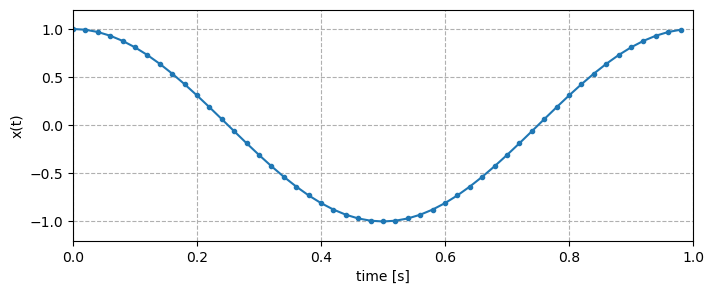

In [14]:
plt.figure(figsize = (8,3))
#plt.title("RMS value of cossine function: {:.4f}".format(np.sqrt(2)/2))
#plt.stem(t, x, 'k', label = r"||x|| =  {:.4f}".format(np.sqrt(np.dot(x,x)/len(x))), basefmt=None)
plt.plot(t, x, marker = '.')
#plt.legend()
plt.xlim((0, 1))
plt.ylim((-1.2, 1.2))
plt.grid(linestyle = '--')
plt.xlabel('time [s]')
plt.ylabel('x(t)');

# Exercícios

Vamos calcular alguns produtos internos.

1. dois cossenos com mesma frequência
2. um seno e um cosseno com mesma frequência
3. dois cossenos de frequência diferente

In [15]:
# 1 dois cossenos com mesma frequência
freq = 10
g_cos = np.cos(2*np.pi*freq*t)
dot_prod = np.dot(g_cos, g_cos)
print("Dot product/len(t) is: {:.19f}".format(dot_prod/len(t)))

Dot product/len(t) is: 0.5000000000000001110


In [15]:
# um seno e um cosseno com mesma frequência
freq1 = 10
freq2 = 50
g_sin = np.cos(2*np.pi*freq1*t)
g_cos = np.cos(2*np.pi*freq2*t)
dot_prod = np.dot(g_sin, g_cos)
print("Dot product/len(t) is: {:.19f}".format(dot_prod/len(t)))

Dot product/len(t) is: -0.0000000000000002487


In [16]:
# dois cossenos de frequência diferente
freq1 = 10
freq2 = 11
g_cos1 = np.cos(2*np.pi*freq1*t)
g_cos2 = np.cos(2*np.pi*freq2*t)
dot_prod = np.dot(g_cos1, g_cos2)
print("Dot product/len(t) is: {:.19f}".format(dot_prod/len(t)))

Dot product/len(t) is: -0.0000000000000006173


## A lição do exemplo

- senos e cossenos são funções ortogonais (e bem básicas). De fato a relação de ortogonalidade pode ser vista da fórmula de Euler

\begin{equation}
\text{e}^{j \omega t} = \cos(\omega t) + j \sin(\omega t)
\tag{11}
\end{equation}

- cossenos de frequência diferente são também ortogonais.

#### De posse deste raciocínio, nós podemos pensar no seguinte: 

Se $f(t)$ for um sinal qualquer, eu posso tentar calcular o tamanho da projeção deste na "direção" de um seno/cosseno com uma dada frequência. 

É exatamente isso que faz uma **Transformada de Fourier**.


\begin{equation}
X(j\omega) = \int_{-\infty}^{\infty}f(t) \text{e}^{-j\omega t}\text{d}t
\tag{12}
\end{equation}

#### Revisão sobre Transformada de Fourier

A transformada de Fourier proporcionará uma intuição importante sobre as dificuldades gerais dos problemas inversos. Tipicamente, ela é ensinada em cursos de processamento de sinais. Você pode revisar algumas aulas na seguinte playlist

<a href="https://www.youtube.com/playlist?list=PLfuiSoAvtFWcs4YnZjHK_naowZhPjzfCT" target="_blank">Playlist de vídeo-aulas sobre números Transformada de Fourier e espectro de sinais.</a>

# Outras normas de vetores

Podemos especificar outras importantes normas de vetores. 

Relembremos que a norma **Euclidiana** é

\begin{equation}
    \left\|\textbf{a}\right\|_2 = \sqrt{\textbf{a} \cdot \textbf{a}} = \sqrt{\textbf{a}^{H} \ \textbf{a}} = \sqrt{\sum\limits_{i = 1}^{N}a_{i}^{*}a_{i}} =\sqrt{\sum\limits_{i = 1}^{N} |a_{i}|^2}
\tag{13}
\end{equation}

Ela é também chamada de norma $\ell_2$ dada a presença dos quadrados no somatório.

Uma norma importante no aprendizado de máquina é a norma $\ell_0$ (zero-norm). Ela conta o número de elementos não nulos de um vetor. É usada em aprendizado de máquina para medir o grau de **esparsidade** de um vetor. No entanto, esta norma leva à problemas de otimização não convexos. Uma norma comumente usada como substituta para medidas de esparsidade é a norma $\ell_1$ (ou Manhattan), dada por

\begin{equation}
    \left\|\textbf{a}\right\|_1 = \sum\limits_{i = 1}^{N} |a_{i}|.
\tag{13}
\end{equation}

Neste caso, a solução de problemas inversos com a imposição de **esparsidade** (apenas alguns elementos da solução são não nulos) torna-se viável. É uma área do aprendizado de máquina chamada *compressed sensing* (CS).

De maneira mais geral, podemos ter a norma $\ell_p$ (para $p\geq1$), dada por

\begin{equation}
    \left\|\textbf{a}\right\|_p = \left(\sum\limits_{i = 1}^{N} |a_{i}|^p\right)^{1/p}.
\tag{14}
\end{equation}

E quando $p\rightarrow \infty$ temos a norma infinito ($\ell_\infty$)


\begin{equation}
    \left\|\textbf{a}\right\|_\infty = \text{max}(|x_1|, |x_2|, \cdots, |x_N|).
\tag{14}
\end{equation}

# Exercícios

Vamos calcular as normas dadas acima para o sinal na próxima célula.

In [17]:
t = np.arange(0, 1, 0.1)
b = np.cos(2*np.pi*1*t)

In [28]:
l2norm = np.sqrt(np.sum(np.abs(b)**2))
rms = np.sqrt(np.sum(np.abs(b)**2)/len(t))
print(r"L_2 norm: {:.4f} / RMS value: {:.4f}".format(l2norm, rms))

l1norm = np.sqrt(np.sum(np.abs(b)))
print(r"L_1 norm: {:.4f}".format(l1norm))

linf_norm = np.amax(np.abs(b))
print(r"L_inf norm: {:.4f}".format(linf_norm))

L_2 norm: 2.2361 / RMS value: 0.7071
L_1 norm: 2.5440
L_inf norm: 1.0000


# Exercícios

Calcule o produto interno e determine se os seguintes pares de vetores $\in \mathbb{R}^4$ são ortogonais ou não.

(a) $\bf{v}_1 = [0.0, 1.0, 0.0, 0.0]^T$ \& $\bf{v}_2 = [0.0, 2.5, 0.0, 0.0]^T$

(b) $\bf{v}_1 = [0.0, 0.7, 0.0, 0.0]^T$ \& $\bf{v}_2 = [0.0, 0.0, 0.0, 1.5]^T$

(c) $\bf{v}_1 = [1.0, 0.0, 0.0, 0.0]^T$ \& $\bf{v}_2 = [0.0, 0.0, 1.0, 0.0]^T$

(d) $\bf{v}_1 = [1.0, 0.0, 1.0, 0.0]^T$ \& $\bf{v}_2 = [0.0, 1.0, 0.0, 0.0]^T$